Choose a sample to run. `sample_id` can be one of:
- mouse_vas_deferens1
- mouse_vas_deferens2
- mouse_femoral_artery
- mouse_bladder
- mouse_trachea
- human_cornea
- insect_leg

In [ ]:
max_angle = 18
interval = 6
n_bscans = int(max_angle/interval)*2+1
anglename = str(max_angle) + '-' + str(interval) + '-' + str(max_angle)

sample_id = 'mouse_vas_deferens1'  # a string that denotes which data to run
data_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/Datasets/' + anglename + '/'  # where is the OCRT input data located?
save_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/' + anglename + '/'  # where to save the tf graph after optimization

# Registration of multiangle B-scans and synthesis of refractive index map
The registration metric is optimized with respect to the deformation model, which in this case is ray propagation through a spatially inhomogeneous refractive index map.

In [2]:
from __future__ import print_function, division
import OCRT
import importlib
importlib.reload(OCRT)
from OCRT import OCRT2D

import tensorflow as tf
tf.compat.v1.disable_eager_execution()
import matplotlib.pyplot as plt
import numpy as np
from time import time
%matplotlib inline

a = OCRT2D(sample_id=sample_id,save_directory=save_directory)

In [3]:
# adjust some parameters, depending on the sample:
if sample_id in ['mouse_bladder', 'mouse_femoral_artery', 'mouse_trachea', 'mouse_vas_deferens1']:
    num_iter = 200
elif sample_id in ['mouse_vas_deferens2']:
    num_iter = 300
elif sample_id in ['insect_leg']:
    num_iter = 500
elif sample_id in ['human_cornea']:
    num_iter = 500
    # this sample is more difficult to register, so use a multiresolution approach:
    a.use_multires = True
    a.size_factor_ = 1  # the final size_factor_ is 8
    a.switch_iter = 250
else:
    raise Exception('invalid sample_id: ' + sample_id)
    
# two tube sizes were used (same inner diameter, but different outer diameter):
if sample_id in ['mouse_vas_deferens1', 'mouse_vas_deferens2', 'mouse_trachea']:
    a.tube_diameter = 1.066  # in mm
else:
    a.tube_diameter = 1.108516

In [4]:
a.load_data_and_resolve_constants(data_directory=data_directory, max_angle = max_angle, angle_step = interval)
a.build_graph()

data loaded: 0.7846031188964844 sec
Instructions for updating:
Use `tf.cast` instead.
Instructions for updating:
Use `tf.cast` instead.
Instructions for updating:
Use `tf.cast` instead.
graph built: 10.487566947937012 sec


0 [0.3953335, 0.0, 0.0, 9.8326935e-05, 0.0005770487] 19.611190795898438


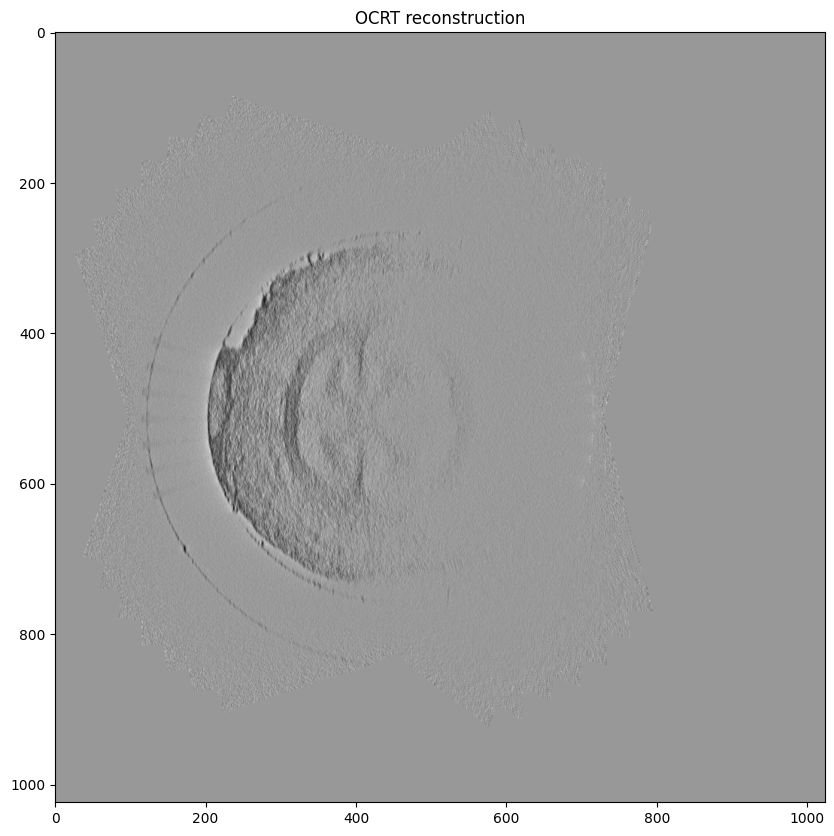

ValueError: Cannot feed value of shape (60, 2) for Tensor coordinate_based_parameters/Bscan_spatial_offsets/Read/ReadVariableOp:0, which has shape (7, 2)

In [ ]:
# run through optimization loop:
losses = list()
feed_dict = a.get_feed_dict()
for i in range(num_iter + 1):
    
    # if using multires, change the pixel resolution of the reconstruction
    if i == a.switch_iter and a.use_multires: 
        feed_dict[a.size_factor] = a.final_size_factor
    
    start = time()
    loss_i, _ = a.sess.run([a.loss_terms, a.train_op], feed_dict=feed_dict)
    losses.append(loss_i)
    print(i, loss_i, time()-start)
    # loss_i is a list of all the contributors to the scalar loss;
    # (see a.loss_terms or a.loss_term_names for names of the regularization terms)
    
    # monitor results periodically:
    if i % 10 == 0:
        recon_i = a.sess.run(a.recon, feed_dict=feed_dict)
        recon_i = recon_i.sum(2)  # only once slice along y contains nonzero values, because we are optimizing 2D
        plt.figure(figsize=(10, 10))
        plt.imshow(recon_i, cmap='gray_r')
        plt.title('OCRT reconstruction')
        plt.show()
        
        RI = a.sess.run(a.RI, feed_dict={a.xz_delta: np.zeros((n_bscans, 2))})  # remove xy_delta shifts
        
        plt.imshow(RI)
        plt.title('refractive index map')
        plt.colorbar()
        plt.show()
        
        plt.plot(losses)
        plt.legend(a.loss_term_names.eval())
        plt.title('loss terms')
        plt.show()

In [ ]:
a.save_graph()  # this graph must be saved in order to run filter optimization below

Created new directory: saved_models_and_variables/mouse_vas_deferens1


# Filter optimization after registration
Freeze the registration/refractive index parameters and only optimize the 2D backprojection filter.

In [ ]:
# remove previous tf graph and variables:
a.sess.close()
tf.compat.v1.reset_default_graph()
del a

In [ ]:
# # Run during debugs when OCRT.py has been changed
# import OCRT
# import importlib
# importlib.reload(OCRT)
# from OCRT import OCRT2D

In [ ]:
# instantiate new object, this time for filter optimization
a = OCRT2D(sample_id=sample_id,save_directory=save_directory)
num_iter = 100
a.infer_backprojection_filter = True
a.use_spatial_shifts = False

# as above, set the tube diameter depending on the sample:
if sample_id in ['mouse_vas_deferens1', 'mouse_vas_deferens2', 'mouse_trachea']:
    a.tube_diameter = 1.066
else:
    a.tube_diameter = 1.108516

a.load_data_and_resolve_constants(data_directory=data_directory, max_angle = max_angle, angle_step = interval)
a.build_graph()

data loaded: 15.477907657623291 sec
INFO:tensorflow:Restoring parameters from saved_models_and_variables/mouse_vas_deferens1/model.ckpt
graph built: 11.544982671737671 sec


0 [0.18286528, 0.037590683] 175.85147380828857


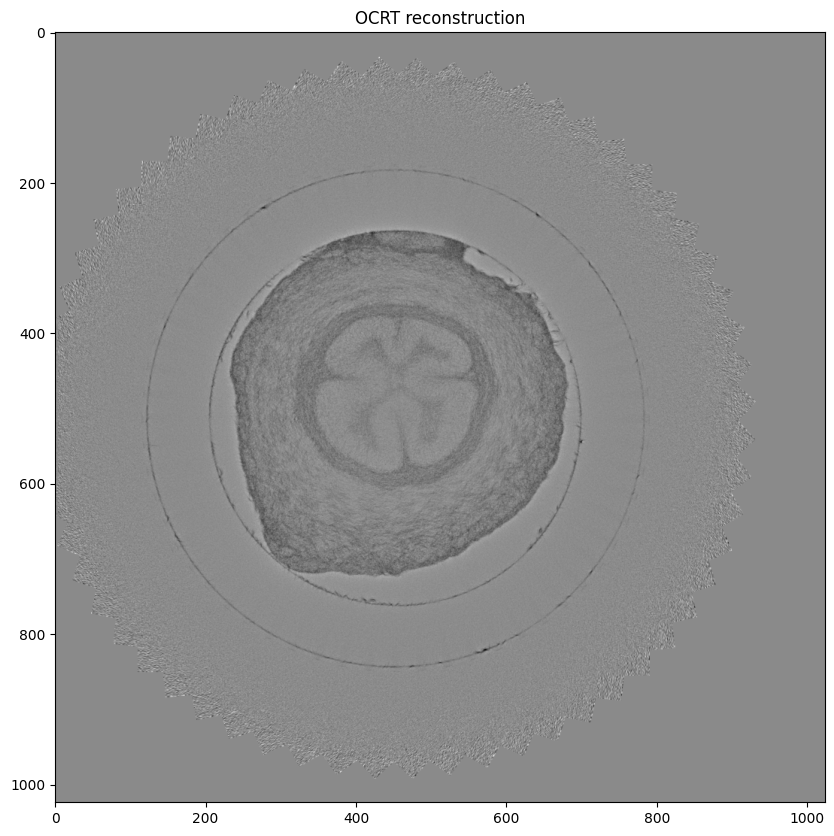

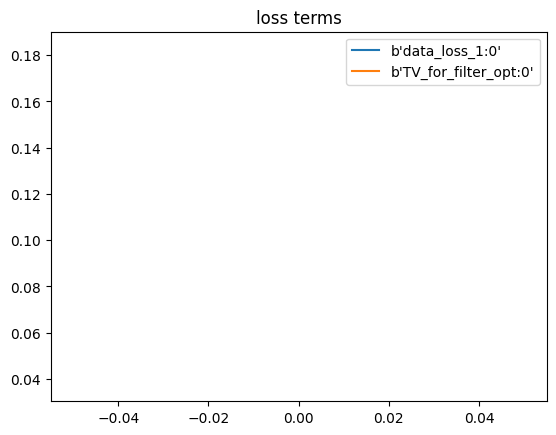

1 [0.18043694, 0.037538674] 173.34462022781372
2 [0.1781537, 0.03748199] 172.64576935768127
3 [0.17589928, 0.03742302] 173.10339379310608
4 [0.1736651, 0.03736274] 173.25153303146362
5 [0.1714876, 0.0373017] 173.15917372703552
6 [0.16938893, 0.037240166] 172.2976198196411
7 [0.1673714, 0.03717822] 172.9653422832489
8 [0.16541713, 0.037115883] 172.12956380844116
9 [0.16351941, 0.03705316] 172.6330964565277
10 [0.16167916, 0.036990132] 173.4565944671631
11 [0.15990329, 0.036926858] 171.86139369010925
12 [0.15820321, 0.036863457] 172.2958743572235
13 [0.15658087, 0.03680003] 172.2534441947937
14 [0.15502298, 0.036736697] 173.74368286132812
15 [0.15352915, 0.036673527] 173.87479329109192
16 [0.15209489, 0.03661055] 173.0407841205597
17 [0.1507233, 0.036547765] 172.0330810546875
18 [0.14942016, 0.03648512] 172.68666553497314
19 [0.14818338, 0.036422547] 173.61263227462769
20 [0.14701119, 0.03635995] 173.69394755363464


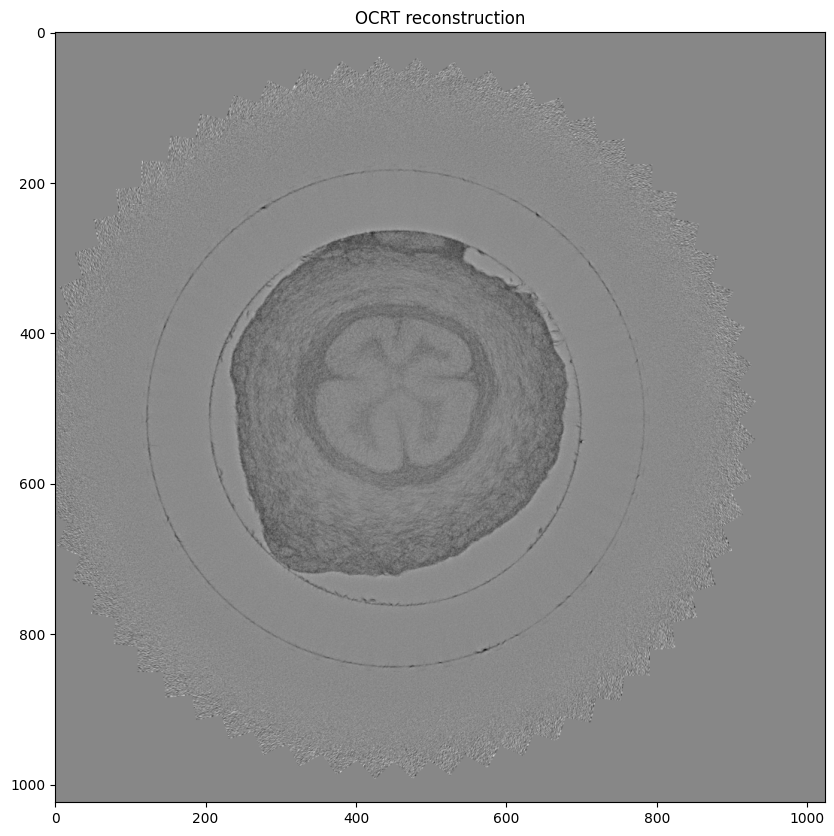

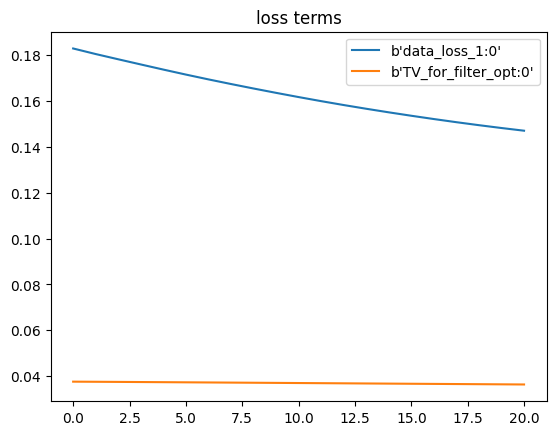

21 [0.14589696, 0.03629724] 174.01942825317383
22 [0.14484093, 0.036234386] 172.4292757511139
23 [0.14383942, 0.036171377] 173.34792828559875
24 [0.14289385, 0.03610824] 172.5590043067932
25 [0.14200142, 0.03604505] 173.38836312294006
26 [0.14116211, 0.03598187] 172.9681453704834
27 [0.14037277, 0.035918783] 173.2164442539215
28 [0.1396313, 0.03585582] 172.79974794387817
29 [0.13893415, 0.035793018] 173.5427529811859
30 [0.13828038, 0.035730354] 173.9486916065216
31 [0.13766555, 0.035667773] 172.57535004615784
32 [0.13709213, 0.035605222] 174.32084727287292
33 [0.13655499, 0.035542622] 174.9039556980133
34 [0.1360534, 0.03547991] 173.16908860206604
35 [0.1355829, 0.035417046] 174.11311173439026
36 [0.13514332, 0.03535404] 173.6264762878418
37 [0.1347313, 0.03529092] 173.22077822685242
38 [0.1343471, 0.035227735] 174.25295567512512
39 [0.1339882, 0.03516454] 173.286479473114
40 [0.1336505, 0.035101388] 172.02809071540833


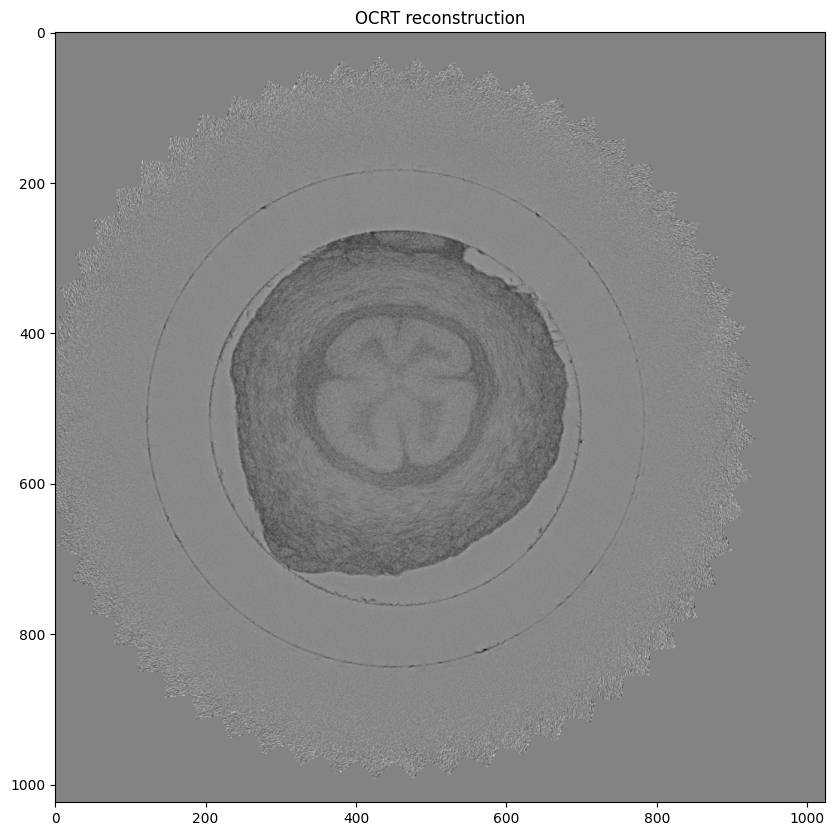

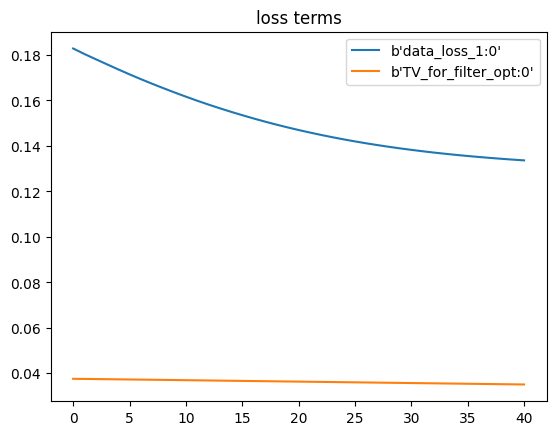

41 [0.1333366, 0.035038322] 173.12456917762756
42 [0.13304001, 0.034975342] 172.81619548797607
43 [0.13276163, 0.034912437] 174.49871969223022
44 [0.13250026, 0.034849558] 172.56669521331787
45 [0.13225463, 0.034786656] 174.26853227615356
46 [0.13202259, 0.034723677] 174.00125336647034
47 [0.1318045, 0.034660593] 173.66369557380676
48 [0.13159828, 0.03459738] 172.7660427093506
49 [0.13140178, 0.034534037] 172.97870564460754
50 [0.13121414, 0.03447061] 172.76994442939758
51 [0.13103649, 0.034407143] 173.4837098121643
52 [0.13086696, 0.034343675] 172.8902039527893
53 [0.13070314, 0.034280233] 173.18883156776428
54 [0.1305476, 0.034216844] 173.72644090652466
55 [0.13039732, 0.034153495] 172.64837265014648
56 [0.13025367, 0.03409018] 173.2781960964203
57 [0.13011432, 0.03402687] 174.2018837928772
58 [0.12997936, 0.03396354] 172.98144030570984
59 [0.12984903, 0.033900164] 172.9375822544098
60 [0.12972324, 0.033836763] 172.19905376434326


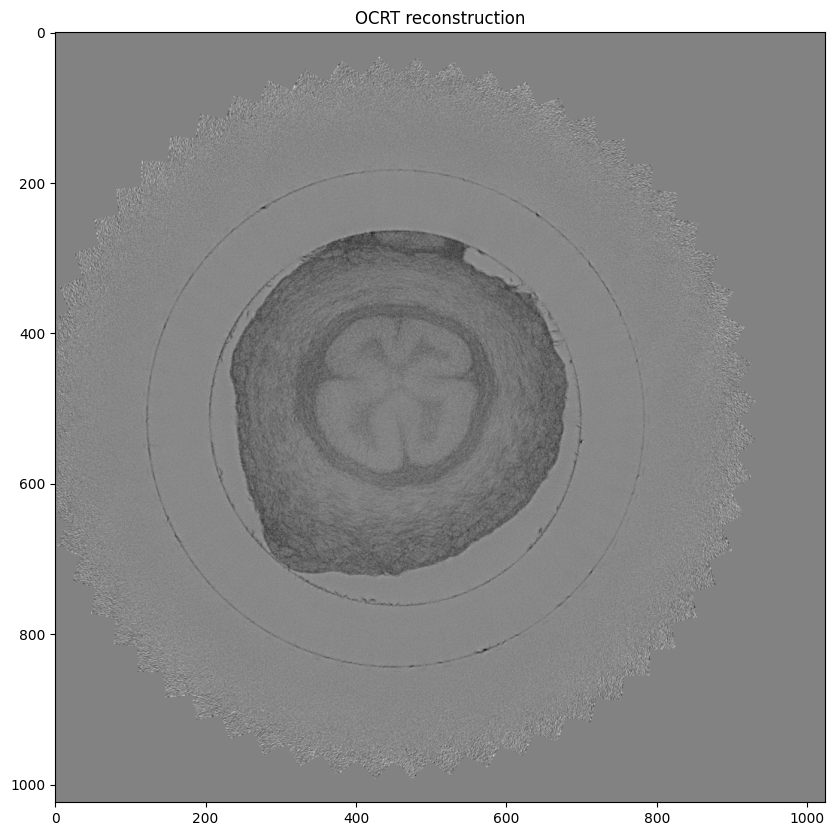

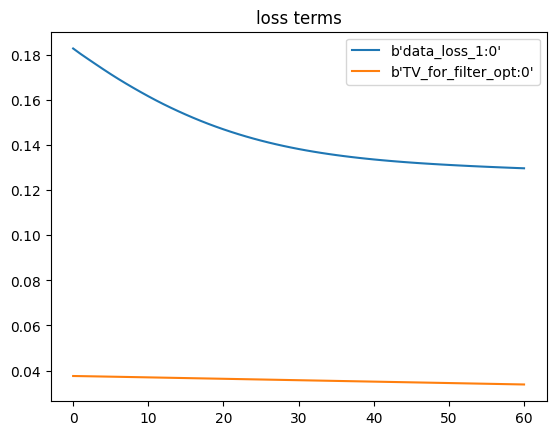

61 [0.12959932, 0.033773325] 173.19397807121277
62 [0.12947775, 0.033709887] 173.54191780090332
63 [0.1293608, 0.033646483] 173.24559903144836
64 [0.12924463, 0.033583134] 173.07808089256287
65 [0.12913173, 0.033519886] 172.0465168952942
66 [0.12902163, 0.033456728] 172.33248805999756
67 [0.12891395, 0.033393666] 172.71047377586365
68 [0.12880781, 0.03333069] 173.30238223075867
69 [0.1287048, 0.033267774] 172.54034662246704
70 [0.12860009, 0.03320491] 172.2993893623352
71 [0.12849745, 0.033142086] 172.28947377204895
72 [0.12839815, 0.033079293] 172.31528186798096
73 [0.1283005, 0.033016555] 173.04818320274353
74 [0.12820525, 0.032953877] 173.3024652004242
75 [0.12811328, 0.03289129] 172.8280017375946
76 [0.12802061, 0.0328288] 172.17493653297424
77 [0.1279289, 0.03276642] 172.62734484672546
78 [0.1278395, 0.032704152] 172.42805933952332
79 [0.12775289, 0.03264199] 172.34617018699646
80 [0.12766652, 0.032579925] 172.73959732055664


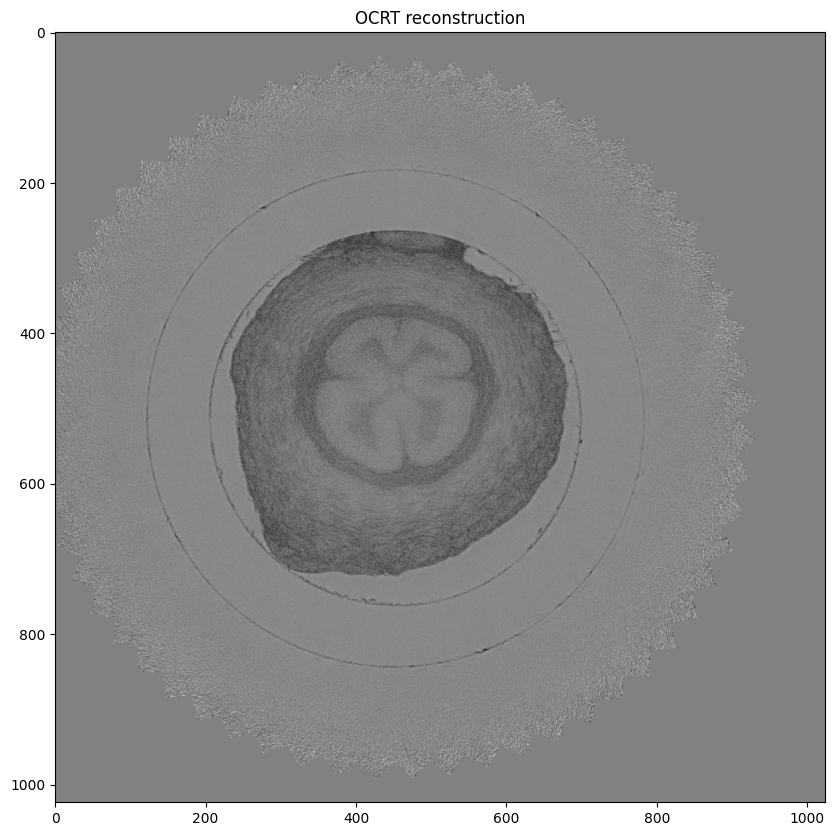

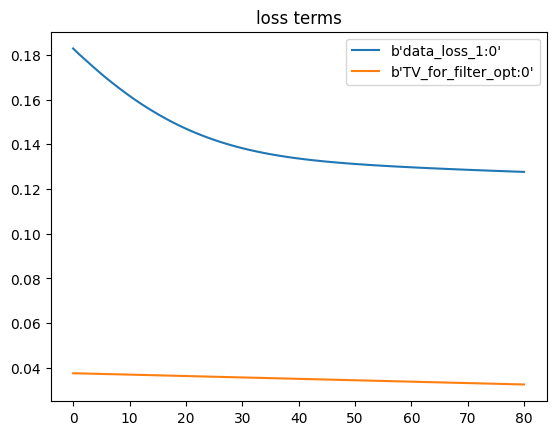

81 [0.12758173, 0.03251794] 171.18420481681824
82 [0.12749738, 0.03245604] 171.96592044830322
83 [0.12741646, 0.032394208] 170.70815873146057
84 [0.1273361, 0.032332458] 172.11523008346558
85 [0.1272572, 0.032270797] 172.0753357410431
86 [0.12718038, 0.032209236] 171.99181199073792
87 [0.12710525, 0.032147784] 171.53797912597656
88 [0.12703036, 0.032086443] 170.7243161201477
89 [0.12695691, 0.032025218] 171.82011079788208
90 [0.12688465, 0.0319641] 171.30978679656982
91 [0.1268126, 0.031903084] 172.43184971809387
92 [0.12674156, 0.03184217] 173.33581686019897
93 [0.12667301, 0.031781334] 171.70503783226013
94 [0.12660535, 0.031720594] 170.98291659355164
95 [0.12653917, 0.031659942] 172.19621086120605
96 [0.12647359, 0.03159938] 171.81996655464172
97 [0.1264091, 0.031538922] 172.4658842086792
98 [0.12634492, 0.031478573] 172.11346006393433
99 [0.12628245, 0.031418327] 171.80084371566772
100 [0.12622204, 0.031358186] 171.6205530166626


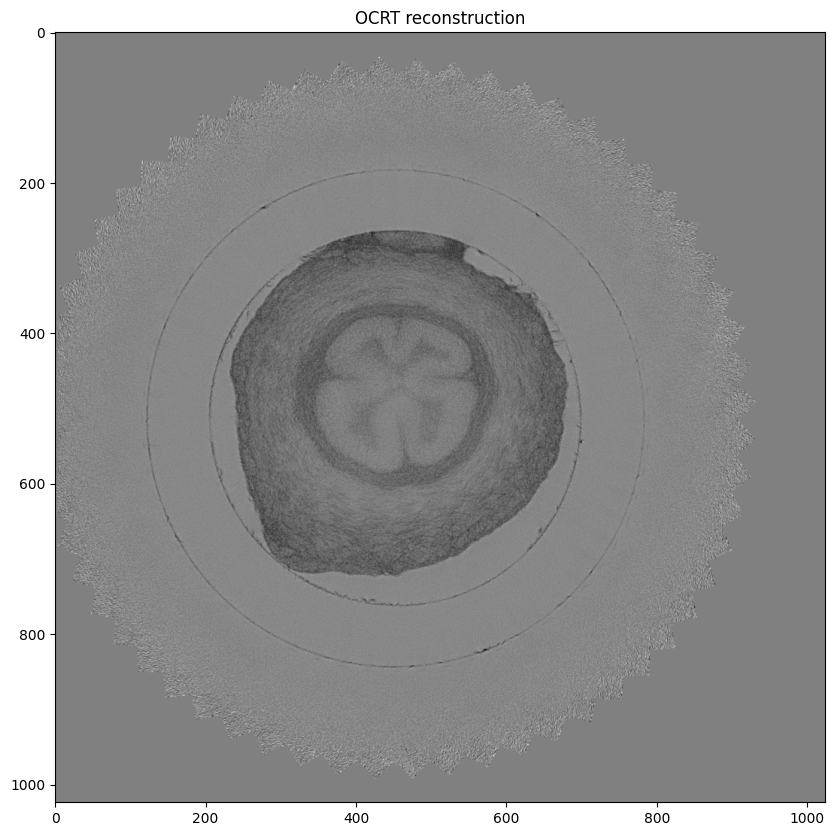

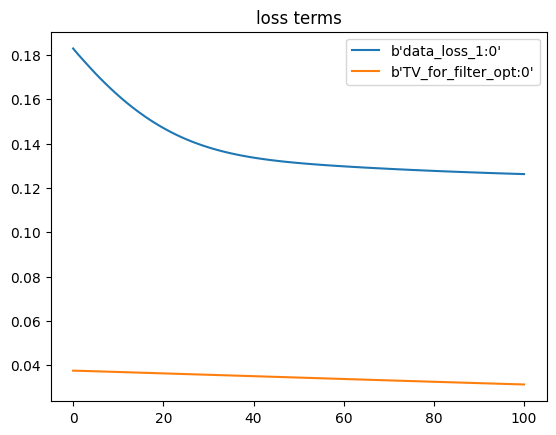

In [ ]:
losses = list()
feed_dict = a.get_feed_dict()
for i in range(num_iter + 1):
    start = time()
    loss_i, _ = a.sess.run([a.loss_terms, a.train_op], feed_dict=feed_dict)
    losses.append(loss_i)
    print(i, loss_i, time()-start)
    
    # monitor results periodically:
    if i % 20 == 0:
        recon_i = a.sess.run(a.recon, feed_dict=feed_dict)
        recon_i = recon_i.sum(2)
        plt.figure(figsize=(10, 10))
        plt.imshow(recon_i, cmap='gray_r')
        plt.title('OCRT reconstruction')
        plt.show()
        
        plt.plot(losses)
        plt.legend(a.loss_term_names.eval())
        plt.title('loss terms')
        plt.show()

In [ ]:
# a.save_graph()  # this graph doesn't need to be saved